<a href="https://colab.research.google.com/github/harshhlf2024-cmyk/Minor-Project/blob/main/Minor%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import Libraries

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

In [58]:
sns.set_theme(style="whitegrid")

## 2. Load Dataset

In [59]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [60]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [61]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand and Check Data Quality

In [62]:
print("Column names:")
df.columns.tolist()

Column names:


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [63]:
print("Data types:")
df.dtypes

Data types:


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [64]:
print("Missing values:")
df.isnull().sum()

Missing values:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [65]:
print("\\nDuplicate rows:")
df.duplicated().sum()

\nDuplicate rows:


np.int64(0)

In [66]:
print("\\nTarget distribution:")
df["Churn"].value_counts()

\nTarget distribution:


,count
Churn,
No,5174
Yes,1869


## 4. Data Cleaning and Preparation

In [67]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0

In [68]:
# Remove unique customer identifier
df = df.drop(columns=["customerID"])

In [69]:
# Remove duplicate rows, if any
df = df.drop_duplicates()

In [70]:
# Convert target into 0 and 1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [71]:
print("Missing values after cleaning:")
df.isnull().sum()


Missing values after cleaning:


,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [72]:
print("Cleaned dataset shape:")
df.shape

Cleaned dataset shape:


(7021, 20)

## 5. Exploratory Data Analysis (At least 4 visualizations)

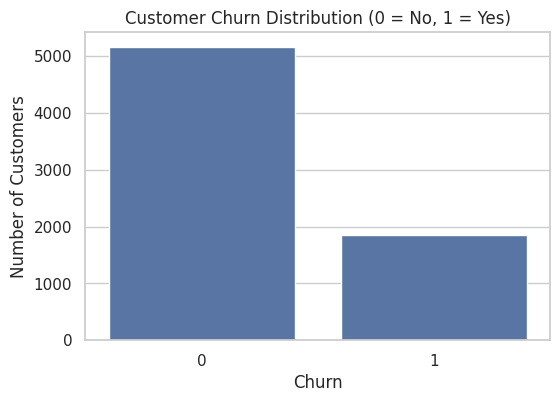

Observation: The graph shows the number of customers who stayed and who left.


In [73]:
# Graph 1: Churn distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution (0 = No, 1 = Yes)")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

print("Observation: The graph shows the number of customers who stayed and who left.")

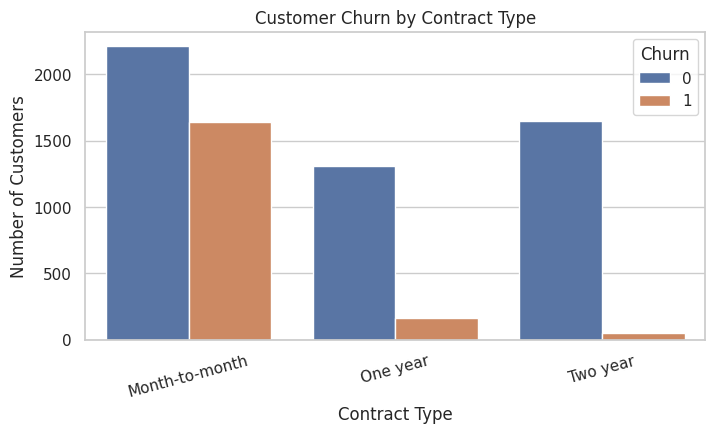

Observation: Compare churn counts across month-to-month, one-year and two-year contracts.


In [74]:
# Graph 2: Churn by contract type
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

print("Observation: Compare churn counts across month-to-month, one-year and two-year contracts.")

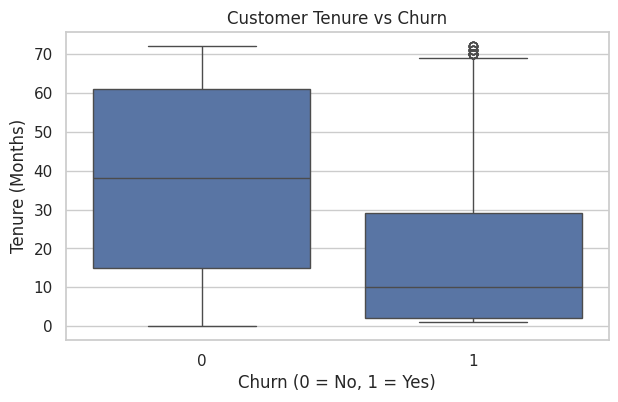

Observation: Compare customer tenure for customers who stayed and customers who left.


In [75]:
# Graph 3: Tenure distribution by churn
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")
plt.show()

print("Observation: Compare customer tenure for customers who stayed and customers who left.")

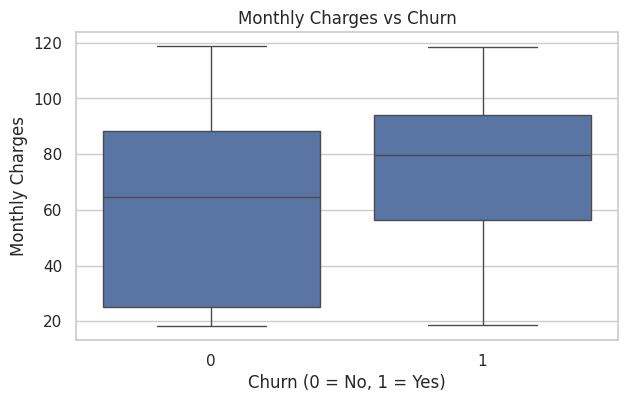

Observation: Compare monthly charges between the two churn groups.


In [76]:
# Graph 4: Monthly charges by churn
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Monthly Charges")
plt.show()

print("Observation: Compare monthly charges between the two churn groups.")

## 6. Select Features and Split Data

In [77]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [78]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

In [79]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols),
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median"))
        ]), numerical_cols)
    ]
)

In [80]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [81]:
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5616
Testing records: 1405


## 7. Train Boosting Models

In [84]:
models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                    max_depth=3, random_state=42)
}

In [85]:
results = []
trained_models = {}

In [88]:
for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })
    trained_models[name] = pipe

In [89]:
results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Gradient Boosting,0.800,0.659,0.508,0.574,0.839
0,AdaBoost,0.799,0.657,0.500,0.568,0.843


## 8. Evaluate the Best Model

In [90]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

In [91]:
print("Best model based on F1 Score:", best_name)
print(classification_report(y_test, best_pred, target_names=["No Churn", "Churn"]))

Best model based on F1 Score: Gradient Boosting
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1033
       Churn       0.66      0.51      0.57       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.72      1405
weighted avg       0.79      0.80      0.79      1405



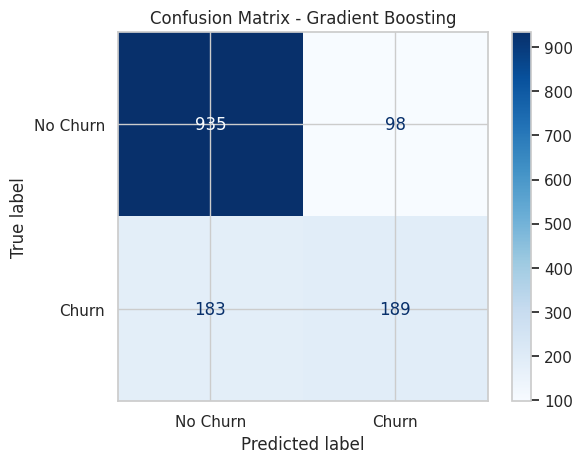

In [92]:
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Confusion Matrix - " + best_name)
plt.show()

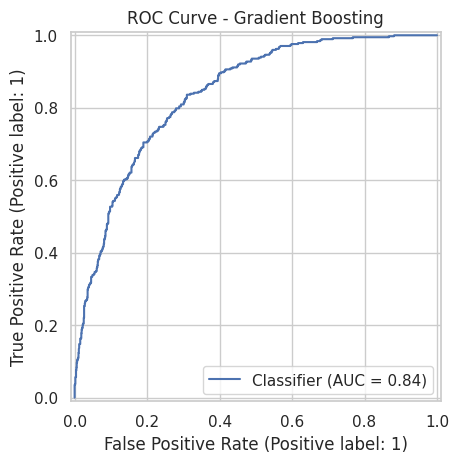

In [93]:
RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title("ROC Curve - " + best_name)
plt.show()